# CaSR Driven Mar to Apr

In [ ]:
path_CaSR_biol='/ocean/jqiu/results/Continuous_CaSR/mar-apr/SalishSea_1d_20230301_20230430_biol_T.nc'
path_HRDPS_biol_mar="/results2/SalishSea/nowcast-green.202111/*mar23/SalishSea_1d_202303*_202303*_biol_T.nc"
path_HRDPS_biol_apr="/results2/SalishSea/nowcast-green.202111/*apr23/SalishSea_1d_202304*_202304*_biol_T.nc"

BIO_VARS = ("nitrate", "diatoms", "flagellates")
N_LAYERS = 20

# "Puget Sound": (75, 125, 225, 280),



## Biol 

Found 61 HRDPS files

Reading CaSR...

Reading HRDPS...


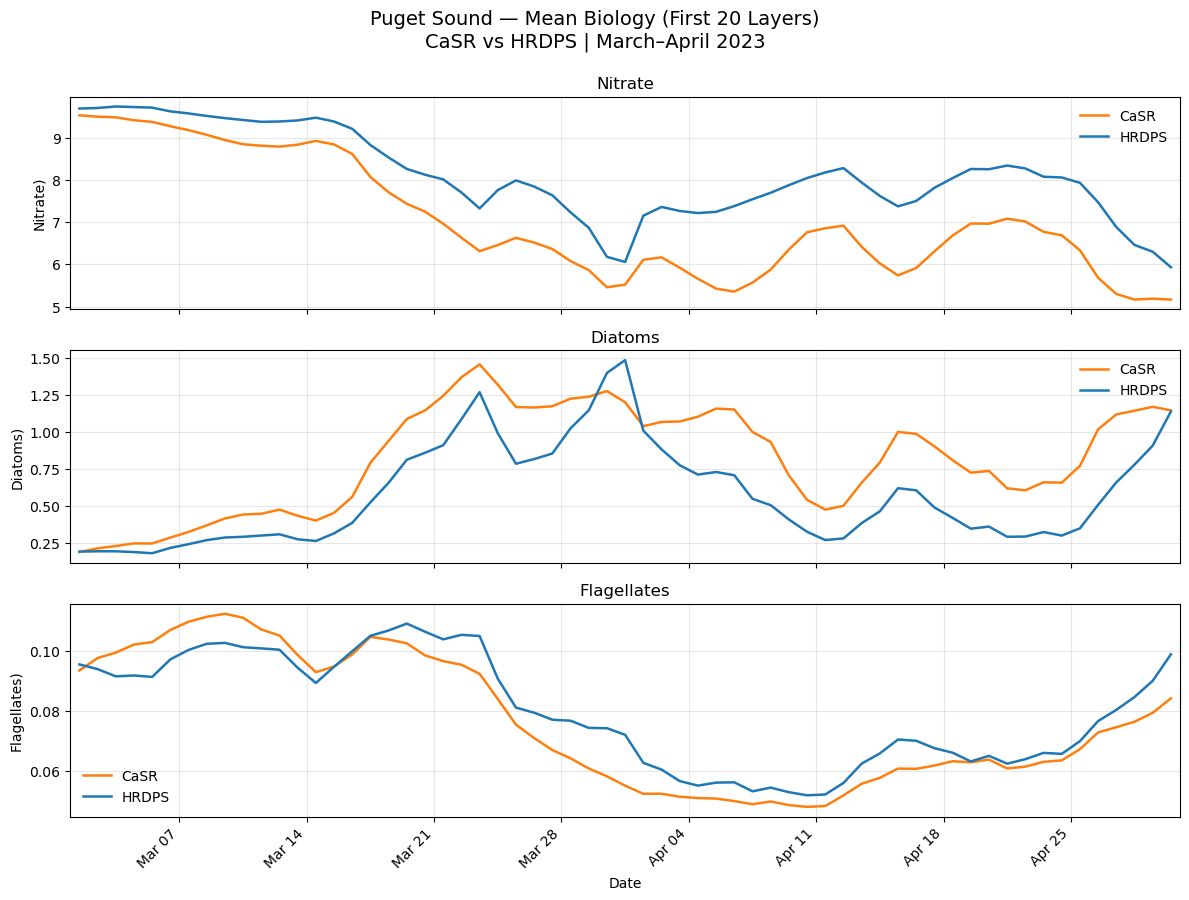

In [ ]:
from pathlib import Path
import glob

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


# ============================================================
# 1. FILE PATHS
# ============================================================

path_CaSR_biol = (
    "/ocean/jqiu/results/Continuous_CaSR/mar-apr/"
    "SalishSea_1d_20230301_20230430_biol_T.nc"
)

path_HRDPS_biol_mar = (
    "/results2/SalishSea/nowcast-green.202111/"
    "*mar23/SalishSea_1d_202303*_202303*_biol_T.nc"
)

path_HRDPS_biol_apr = (
    "/results2/SalishSea/nowcast-green.202111/"
    "*apr23/SalishSea_1d_202304*_202304*_biol_T.nc"
)


# ============================================================
# 2. SETTINGS
# ============================================================

BIO_VARS = ("nitrate", "diatoms", "flagellates")

N_LAYERS = 20

# Puget Sound
j0, j1, i0, i1 = 75, 125, 225, 280

COLORS = {
    "CaSR": "tab:orange",
    "HRDPS": "tab:blue",
}

START_DATE = "2023-03-01"
END_DATE = "2023-04-30"


# ============================================================
# 3. GET HRDPS FILES
# ============================================================

hrdps_files = sorted(
    set(
        glob.glob(path_HRDPS_biol_mar)
        + glob.glob(path_HRDPS_biol_apr)
    )
)

print(f"Found {len(hrdps_files)} HRDPS files")

if not hrdps_files:
    raise FileNotFoundError("No HRDPS biol files found!")

if not Path(path_CaSR_biol).exists():
    raise FileNotFoundError(path_CaSR_biol)


# ============================================================
# 4. FUNCTION: SPATIAL + VERTICAL MEAN
# ============================================================

def calculate_mean(ds, var):

    if var not in ds:
        print(f"WARNING: {var} not found")
        return None

    data = ds[var]

    # Select Puget Sound
    data = data.isel(
        y=slice(j0, j1),
        x=slice(i0, i1),
    )

    # First 20 vertical layers
    depth_dims = [
        d for d in data.dims
        if d.startswith("depth") or d.startswith("s_rho")
    ]

    if depth_dims:
        depth_dim = depth_dims[0]

        data = data.isel({
            depth_dim: slice(0, N_LAYERS)
        })

    # Remove invalid values
    data = data.where(np.isfinite(data))

    # Mean across depth, y, x
    mean_dims = [
        d for d in data.dims
        if d != "time_counter"
    ]

    mean_data = data.mean(
        dim=mean_dims,
        skipna=True
    )

    return mean_data.load()


# ============================================================
# 5. READ CaSR
# ============================================================

results = {
    "CaSR": {},
    "HRDPS": {},
}

print("\nReading CaSR...")

with xr.open_dataset(path_CaSR_biol) as ds:

    for var in BIO_VARS:

        results["CaSR"][var] = calculate_mean(ds, var)


# ============================================================
# 6. READ HRDPS
# ============================================================

print("\nReading HRDPS...")

# Combine all daily files along time
ds_hrdps = xr.open_mfdataset(
    hrdps_files,
    combine="by_coords",
    parallel=False,
)

try:
    for var in BIO_VARS:

        results["HRDPS"][var] = calculate_mean(
            ds_hrdps, var
        )

finally:
    ds_hrdps.close()


# ============================================================
# 7. PLOT: 3 x 1
# ============================================================

fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 9),
    sharex=True
)

for ax, var in zip(axes, BIO_VARS):

    for model in ["CaSR", "HRDPS"]:

        data = results[model][var]

        if data is None:
            continue

        ax.plot(
            data.time_counter.values,
            data.values,
            label=model,
            color=COLORS[model],
            linewidth=1.8,
        )

    ax.set_ylabel(
        f"{var.capitalize()})"
    )

    ax.set_title(
        var.capitalize(),
        fontsize=12
    )

    ax.grid(alpha=0.3)

    ax.legend(frameon=False)


# ============================================================
# 8. FORMATTING
# ============================================================

axes[-1].set_xlabel("Date")

axes[-1].xaxis.set_major_locator(
    mdates.WeekdayLocator(interval=1)
)

axes[-1].xaxis.set_major_formatter(
    mdates.DateFormatter("%b %d")
)

axes[-1].set_xlim(
    np.datetime64(START_DATE),
    np.datetime64(END_DATE) + np.timedelta64(1, "D")
)

plt.setp(
    axes[-1].get_xticklabels(),
    rotation=45,
    ha="right"
)

fig.suptitle(
    "Puget Sound Top 20 Layers\n"
    "Mar–Apr 2023",
    fontsize=14,
    y=0.995
)

plt.tight_layout()

plt.show()

Found 61 HRDPS files

Reading land-sea mask...
Mask shape: (20, 50, 55)
Water points: 21324

Reading CaSR...

Reading HRDPS...


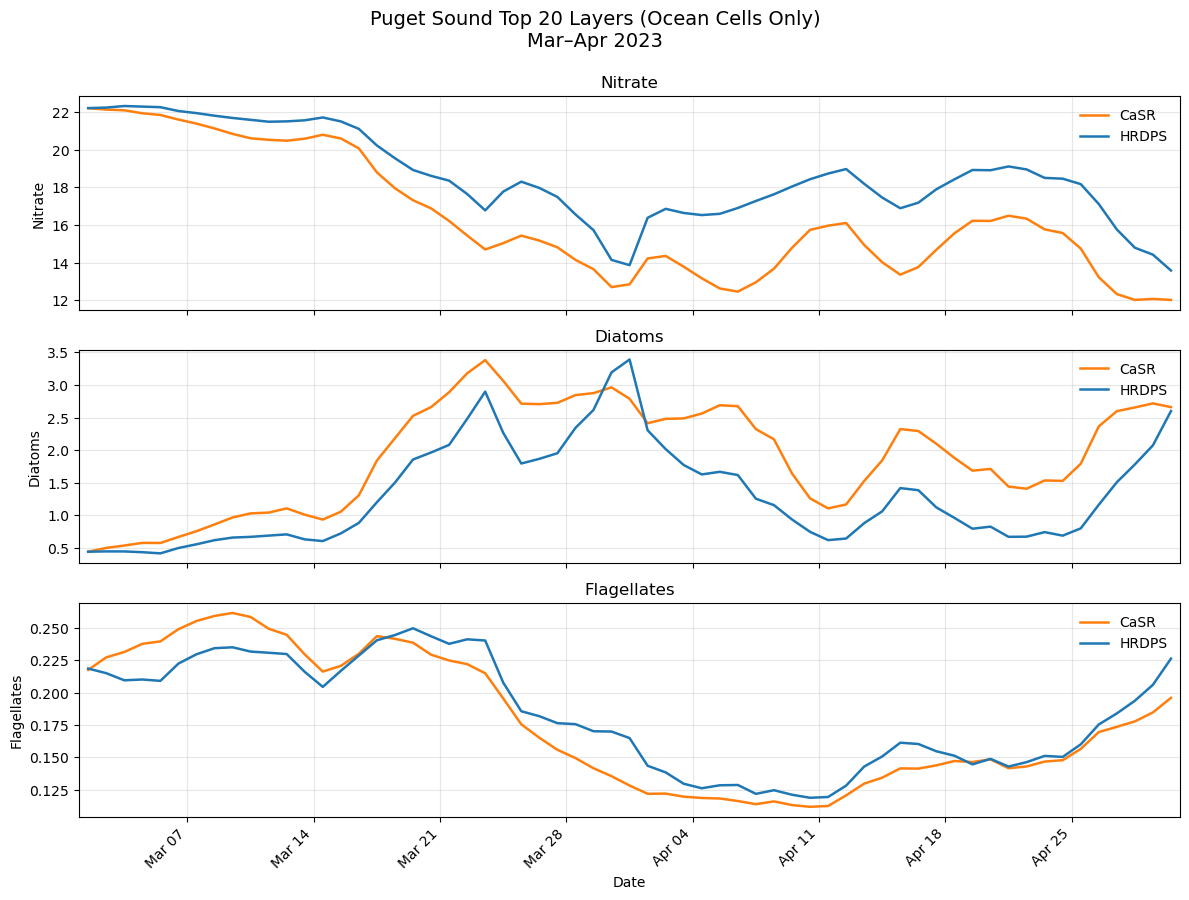

In [3]:

from pathlib import Path
import glob

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


# ============================================================
# 1. FILE PATHS
# ============================================================

path_CaSR_biol = (
    "/ocean/jqiu/results/Continuous_CaSR/mar-apr/"
    "SalishSea_1d_20230301_20230430_biol_T.nc"
)

path_HRDPS_biol_mar = (
    "/results2/SalishSea/nowcast-green.202111/"
    "*mar23/SalishSea_1d_202303*_202303*_biol_T.nc"
)

path_HRDPS_biol_apr = (
    "/results2/SalishSea/nowcast-green.202111/"
    "*apr23/SalishSea_1d_202304*_202304*_biol_T.nc"
)

path_grid = "/ocean/jqiu/Grid/mesh_mask202108.nc"


# ============================================================
# 2. SETTINGS
# ============================================================

BIO_VARS = ("nitrate", "diatoms", "flagellates")

N_LAYERS = 20

# Puget Sound
j0, j1, i0, i1 = 75, 125, 225, 280

COLORS = {
    "CaSR": "tab:orange",
    "HRDPS": "tab:blue",
}

START_DATE = "2023-03-01"
END_DATE = "2023-04-30"


# ============================================================
# 3. GET HRDPS FILES
# ============================================================

hrdps_files = sorted(
    set(
        glob.glob(path_HRDPS_biol_mar)
        + glob.glob(path_HRDPS_biol_apr)
    )
)

print(f"Found {len(hrdps_files)} HRDPS files")

if not hrdps_files:
    raise FileNotFoundError("No HRDPS biol files found!")

if not Path(path_CaSR_biol).exists():
    raise FileNotFoundError(path_CaSR_biol)

if not Path(path_grid).exists():
    raise FileNotFoundError(path_grid)


# ============================================================
# 4. READ LAND-SEA MASK
# ============================================================

print("\nReading land-sea mask...")

with xr.open_dataset(path_grid) as ds_grid:

    # tmask dimensions: (t, z, y, x)
    tmask = ds_grid["tmask"].isel(
        t=0,
        z=slice(0, N_LAYERS),
        y=slice(j0, j1),
        x=slice(i0, i1),
    ).load()

# True = water, False = land
tmask = (tmask == 1)

print("Mask shape:", tmask.shape)
print("Water points:", int(tmask.sum().item()))


# ============================================================
# 5. FUNCTION: SPATIAL + VERTICAL MEAN
# ============================================================

def calculate_mean(ds, var):

    if var not in ds:
        print(f"WARNING: {var} not found")
        return None

    data = ds[var]

    # Select Puget Sound
    data = data.isel(
        y=slice(j0, j1),
        x=slice(i0, i1),
    )

    # Identify vertical dimension
    depth_dims = [
        d for d in data.dims
        if d.startswith("depth") or d.startswith("s_rho")
    ]

    if depth_dims:
        depth_dim = depth_dims[0]

        # First 20 vertical layers
        data = data.isel({
            depth_dim: slice(0, N_LAYERS)
        })

        # Make mask dimensions match data
        mask = xr.DataArray(
            tmask.values[:data.sizes[depth_dim], :, :],
            dims=(depth_dim, "y", "x"),
            coords={
                depth_dim: data[depth_dim],
                "y": data["y"],
                "x": data["x"],
            },
        )

    else:
        # For variables without vertical dimension
        mask = xr.DataArray(
            tmask.values[0, :, :],
            dims=("y", "x"),
            coords={
                "y": data["y"],
                "x": data["x"],
            },
        )

    # Remove land points (tmask = 0)
    data = data.where(mask)

    # Remove any other invalid values
    data = data.where(np.isfinite(data))

    # Mean across depth, y, x
    mean_dims = [
        d for d in data.dims
        if d != "time_counter"
    ]

    mean_data = data.mean(
        dim=mean_dims,
        skipna=True
    )

    return mean_data.load()


# ============================================================
# 6. READ CaSR
# ============================================================

results = {
    "CaSR": {},
    "HRDPS": {},
}

print("\nReading CaSR...")

with xr.open_dataset(path_CaSR_biol) as ds:

    for var in BIO_VARS:

        results["CaSR"][var] = calculate_mean(ds, var)


# ============================================================
# 7. READ HRDPS
# ============================================================

print("\nReading HRDPS...")

ds_hrdps = xr.open_mfdataset(
    hrdps_files,
    combine="by_coords",
    parallel=False,
)

try:
    for var in BIO_VARS:

        results["HRDPS"][var] = calculate_mean(
            ds_hrdps, var
        )

finally:
    ds_hrdps.close()


# ============================================================
# 8. PLOT: 3 x 1
# ============================================================

fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 9),
    sharex=True
)

for ax, var in zip(axes, BIO_VARS):

    for model in ["CaSR", "HRDPS"]:

        data = results[model][var]

        if data is None:
            continue

        ax.plot(
            data.time_counter.values,
            data.values,
            label=model,
            color=COLORS[model],
            linewidth=1.8,
        )

    ax.set_ylabel(var.capitalize())

    ax.set_title(
        var.capitalize(),
        fontsize=12
    )

    ax.grid(alpha=0.3)

    ax.legend(frameon=False)


# ============================================================
# 9. FORMATTING
# ============================================================

axes[-1].set_xlabel("Date")

axes[-1].xaxis.set_major_locator(
    mdates.WeekdayLocator(interval=1)
)

axes[-1].xaxis.set_major_formatter(
    mdates.DateFormatter("%b %d")
)

axes[-1].set_xlim(
    np.datetime64(START_DATE),
    np.datetime64(END_DATE) + np.timedelta64(1, "D")
)

plt.setp(
    axes[-1].get_xticklabels(),
    rotation=45,
    ha="right"
)

fig.suptitle(
    "Puget Sound Top 20 Layers (Ocean Cells Only)\n"
    "Mar–Apr 2023",
    fontsize=14,
    y=0.995
)

plt.tight_layout()

plt.show()
